# 11 · Faithful vs corrected

**Question.** What do the paper's printed choices cost (rounded constraint points, Maclaurin sources, hand-picked PDE invariants), and do the corrected variants remove it?

In [1]:
from pathlib import Path

from pihm import plotting
from pihm.pipeline.results import Results

results = Results.at(Path("..").resolve())
CAMPAIGNS = ("p2_reproduction",)
plotting.apply_style()
print(results.describe(CAMPAIGNS))

p2_reproduction: 327 records, 327 ok


In [2]:
from IPython.display import Markdown, display

from pihm.pipeline.summary import cases

rows = results.rows("p2_reproduction")
variants = {
    variant: cases(rows, variant=variant, label="", truncation="none")
    for variant in ("faithful", "corrected")
}


def error(problem, variant, n, column="field_err_linf"):
    """Return a variant's value of a column for a problem at n."""
    return variants[variant][(problem, variant, n)][column]


top = {}
for problem, _, n in variants["corrected"]:
    if (problem, "faithful", n) in variants["faithful"] and not problem.startswith("R6"):
        top[problem] = max(n, top.get(problem, n))
ratios = {p: error(p, "faithful", n) / error(p, "corrected", n) for p, n in top.items()}
same = sorted(p for p, x in ratios.items() if abs(x - 1.0) < 1e-6)
better = sorted(p for p in ratios if p not in same)
spread = [ratios[p] for p in better]
tau = cases(rows, label="tau ablation")
ablation = [
    row["field_err_linf"] / error(p, "faithful", n)
    for (p, _, n), row in tau.items()
    if (p, "faithful", n) in variants["faithful"] and row["trusted"]
]
lines = [
    f"- At each panel's largest n, the corrected variant's field error is below the faithful "
    f"one's by ×{min(spread):.2g} to ×{max(spread):.2g} on {', '.join(better)}; on "
    f"{', '.join(same)} the two are the same construction.",
    "- The PDE panels' gap Δ, faithful against corrected: "
    + "; ".join(
        f"{p} at n = {n}, {error(p, 'faithful', n, 'gap'):.1e} against "
        f"{error(p, 'corrected', n, 'gap'):.1e}"
        for p, n in sorted(top.items())
        if p.startswith("R5")
    )
    + ".",
    f"- The tau-truncation ablation's field error is ×{min(ablation):.2g} to ×{max(ablation):.2g} "
    "the paper's least squares, where its reference is trusted.",
]
display(Markdown("\n".join(lines)))

- At each panel's largest n, the corrected variant's field error is below the faithful one's by ×1.5e+02 to ×3e+12 on R3c, R3d, R4a, R4b, R4c, R4d, R5a, R5b, R5c; on R2a, R2b, R2c, R3a, R3b the two are the same construction.
- The PDE panels' gap Δ, faithful against corrected: R5a at n = 6, 1.9e-21 against 3.2e+00; R5b at n = 6, 1.5e-23 against 4.3e-01; R5c at n = 6, 6.8e-19 against 5.5e-01.
- The tau-truncation ablation's field error is ×0.16 to ×12 the paper's least squares, where its reference is trusted.

Fig. 5 (sources and constraint points): the field error against n. A faithful error that stops
falling is a floor no resolution removes. The grey line is the SVD reference's own error bound.

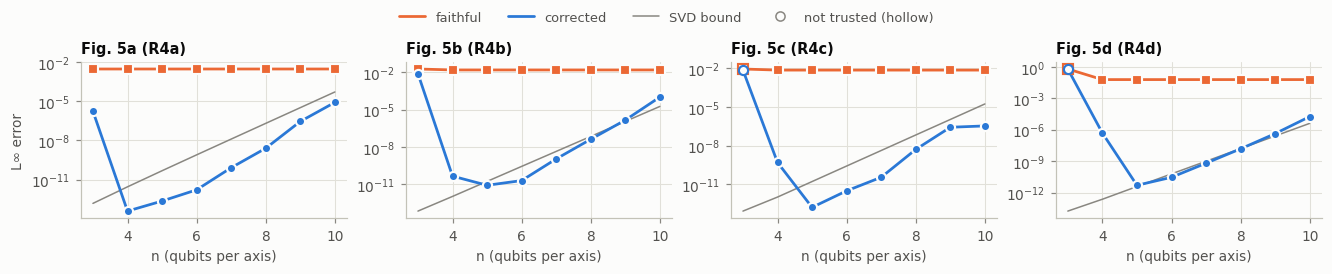

In [3]:
plotting.convergence(rows, ["R4a", "R4b", "R4c", "R4d"]);

Fig. 5d at its printed n: the error under each choice of source and constraint point. Only both
corrections together remove it.

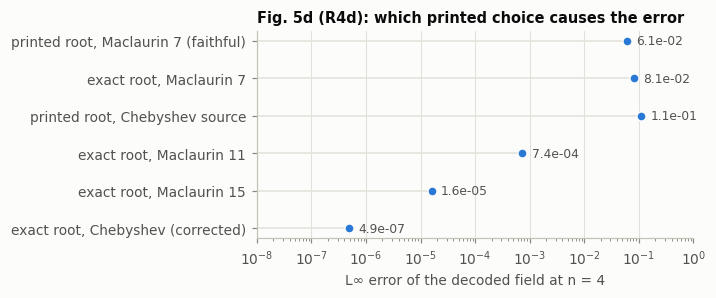

In [4]:
plotting.maclaurin_order(rows);

Fig. 6 (the PDEs): the field error, then the gap. The paper's invariant sets leave the solution
undetermined in the continuum, so the faithful gap collapses as competing modes become
representable.

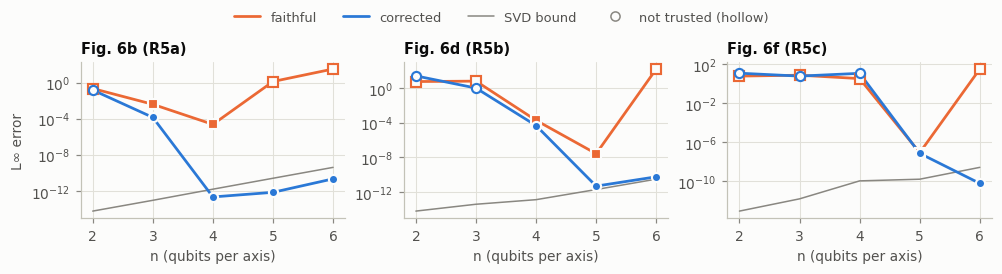

In [5]:
plotting.convergence(rows, ["R5a", "R5b", "R5c"], columns=3);

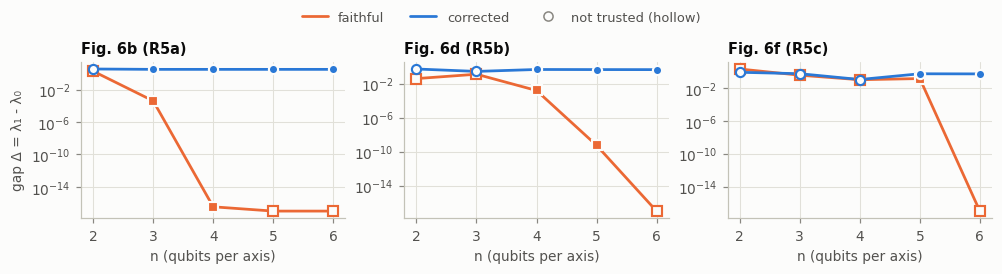

In [6]:
plotting.gap_collapse(rows, ["R5a", "R5b", "R5c"]);

Fig. 3: the paper's least squares against the tau-truncation ablation, whose kernel
is exact. The corrected variant is the faithful one here, so its line covers the faithful line.

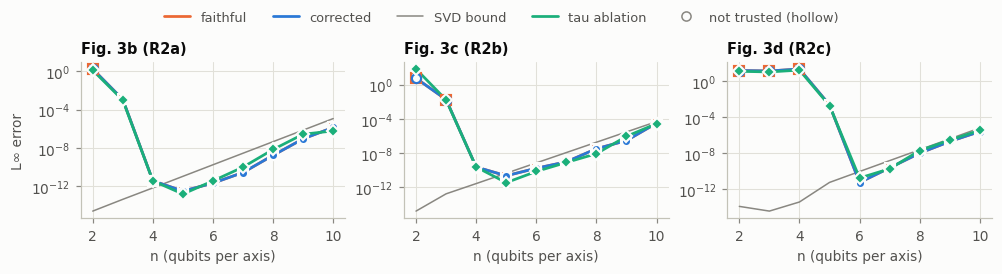

In [7]:
plotting.convergence(rows, ["R2a", "R2b", "R2c"], extra=("tau ablation", "faithful"), columns=3);

**What this does not show.** Figs 3 and 4's corrected variants are the faithful ones (R2, R3a,
R3b) or divide out a branch point (R3c, R3d); the doubled space (R6) is notebook 12's. These are
classical ground states.